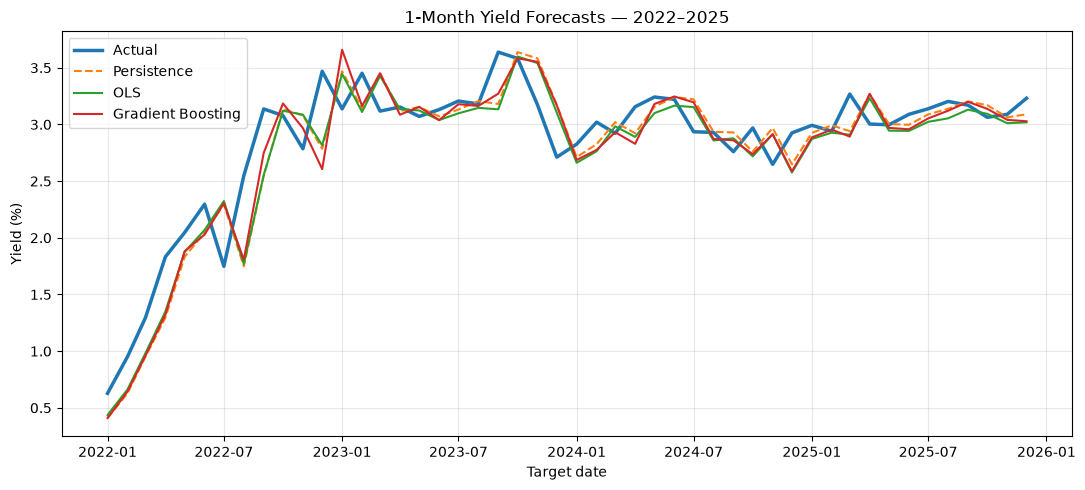

Saved: ../figures/yield_forecast_1m.pdf


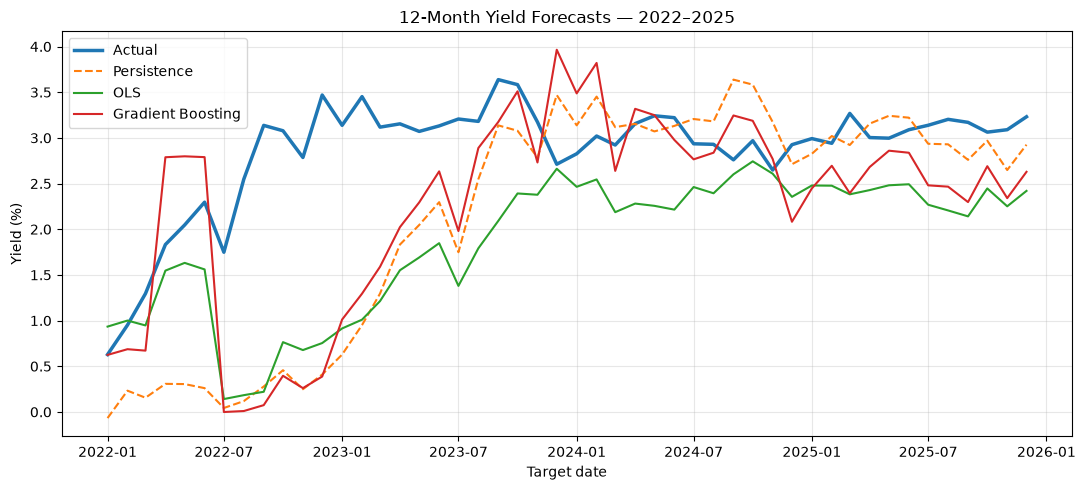

Saved: ../figures/yield_forecast_12m.pdf


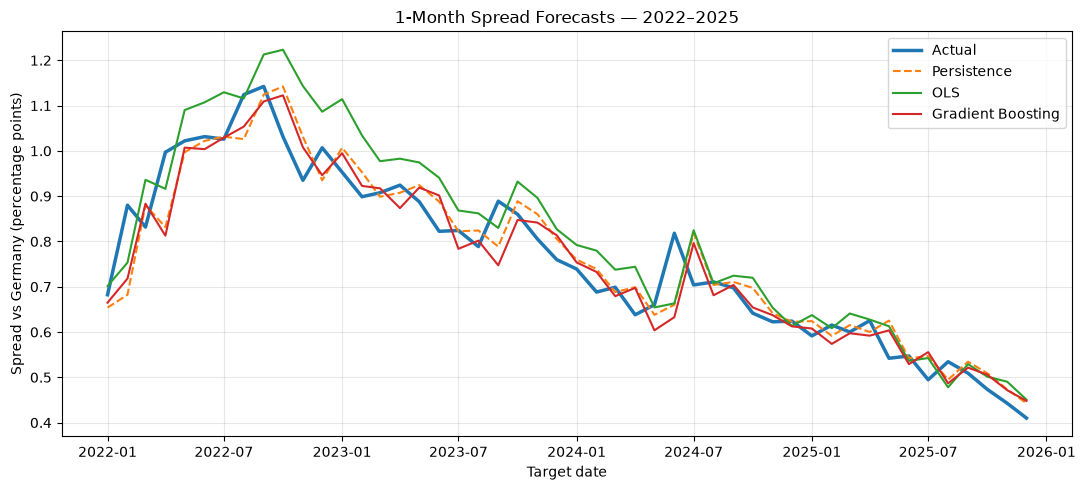

Saved: ../figures/spread_forecast_1m.pdf


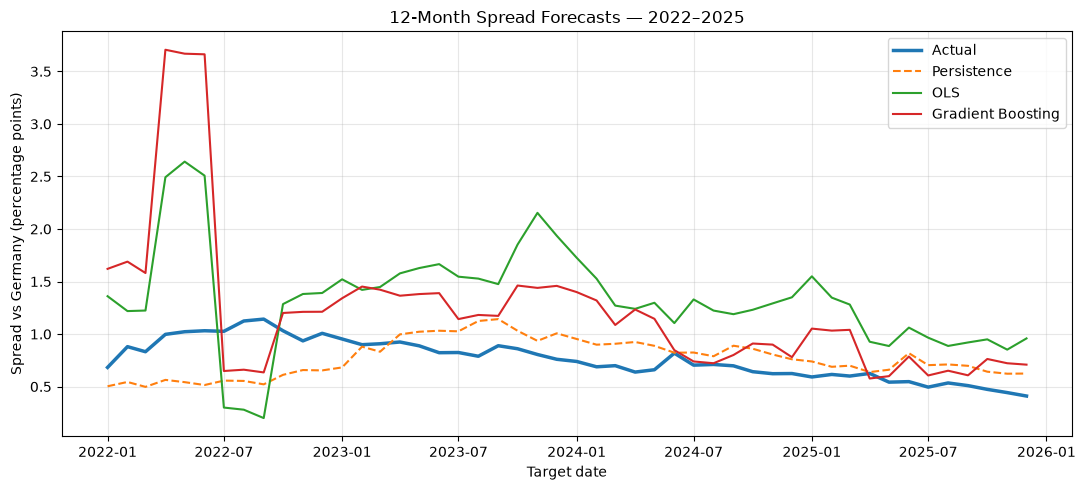

Saved: ../figures/spread_forecast_12m.pdf


In [1]:

# STEP 25B — Plot forecasts from the exported data

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df_plot = pd.read_csv(
    "../data/processed/forecast_predictions_2022_2025.csv",
    parse_dates=["Target_Date"]
)

output_dir = Path("../figures")
output_dir.mkdir(exist_ok=True)

for variable in ["Yield", "Spread"]:
    for horizon in [1, 12]:

        subset = df_plot[
            (df_plot["Variable"] == variable) &
            (df_plot["Horizon"] == horizon)
        ]

        monthly = subset.groupby("Target_Date")[
            ["Actual", "Persistence", "OLS", "Gradient Boosting"]
        ].mean().sort_index()

        fig, ax = plt.subplots(figsize=(11, 5))

        ax.plot(monthly.index, monthly["Actual"],
                label="Actual", linewidth=2.5)
        ax.plot(monthly.index, monthly["Persistence"],
                label="Persistence", linestyle="--")
        ax.plot(monthly.index, monthly["OLS"], label="OLS")
        ax.plot(monthly.index, monthly["Gradient Boosting"],
                label="Gradient Boosting")

        ax.set_title(
            f"{horizon}-Month {variable} Forecasts — 2022–2025"
        )
        ax.set_ylabel(
            "Yield (%)" if variable == "Yield"
            else "Spread vs Germany (percentage points)"
        )
        ax.set_xlabel("Target date")
        ax.legend()
        ax.grid(alpha=0.3)

        plt.tight_layout()

        filename = f"{variable.lower()}_forecast_{horizon}m.pdf"
        plt.savefig(output_dir / filename, bbox_inches="tight")
        plt.show()

        print("Saved:", output_dir / filename)


In [2]:

import pandas as pd

macro = pd.read_csv(
    "../data/processed/sovereign_spreads_lagged.csv",
    parse_dates=["Date"]
)

check = macro[
    (macro["Country"] == "FR") &
    (macro["Date"].between("2021-01-01", "2021-09-01"))
]

display(check[[
    "Date",
    "GDP_Growth_lag4q",
    "Deficit_Surplus_lag4q",
    "Debt_GDP_lag4q",
    "Current_Account_lag4q"
]])


,Date,GDP_Growth_lag4q,Deficit_Surplus_lag4q,Debt_GDP_lag4q,Current_Account_lag4q
1500,2021-01-01,-5.0,-8.7,101.2,-2.5
1501,2021-02-01,-5.0,-8.7,101.2,-2.5
1502,2021-03-01,-5.0,-8.7,101.2,-2.5
1503,2021-04-01,-12.2,-16.0,113.0,-4.3
1504,2021-05-01,-12.2,-16.0,113.0,-4.3
1505,2021-06-01,-12.2,-16.0,113.0,-4.3
1506,2021-07-01,15.1,-6.8,115.3,-2.5
1507,2021-08-01,15.1,-6.8,115.3,-2.5
1508,2021-09-01,15.1,-6.8,115.3,-2.5
